# Les mathématiques au service du cœur : du médicament au stent… et à l'IA
**Fête de la Science 2026 — Bilel Charfi (ESPRIT), bilel.charfi@esprit.tn**

Ce notebook refait **tous les calculs et toutes les figures** de la présentation et du rapport technique (`rapport_technique.pdf`).

* **Partie A** — modèles et simulations : médicament, prises répétées, régression, descente de gradient, loi de Poiseuille, stent, réseau de neurones informé par l'équation.
* **Partie B** — vraies données (théophylline, 12 patients) : estimation de la demi-vie, modèle à deux phases, comparaison modèle mathématique / apprentissage automatique.

Installation : `pip install -r requirements.txt`, puis *Run All*. Les figures s'affichent ici et sont aussi enregistrées dans `figures/`.

## Partie A — Modèles et simulations

Les mathématiques au service du cœur : du médicament au stent… et à l'IA
Fête de la Science 2026 — Bilel Charfi (ESPRIT)

Ce script refait TOUS les calculs et simulations de la présentation et
enregistre les graphiques dans le dossier « figures/ ».

    1. Pharmacocinétique : C(t) = C0·e^(−kt), demi-vie, temps sous 25 mg/L
    2. Prises répétées : suite C_{n+1} = q·C_n + 100 et sa limite
    3. Machine learning : régression linéaire sur ln C pour retrouver k
    4. Descente de gradient sur la même erreur
    5. Loi de Poiseuille : effet de r⁴ et sensibilité (dérivée)
    6. Stent : géométrie d'une cellule en losange (trigonométrie, Pythagore)
    7. Mini réseau de neurones « informé par l'équation » (idée des PINN)

Les vraies mesures (théophylline) sont traitées dans donnees_reelles.py.
Les données de « mesures » sont SIMULÉES (bruit aléatoire, graine fixée) :
les résultats sont donc reproductibles à l'identique.

In [1]:
import math
import os

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.optimize import minimize

# ----------------------------------------------------------------------------
# Mise en forme commune des graphiques (couleurs de la présentation)
# ----------------------------------------------------------------------------
RED, NAVY, BLUE, BG, GREY = "#B22234", "#1B2A4A", "#4A90D9", "#FAFAF7", "#6B768C"
plt.rcParams.update({
    "mathtext.fontset": "cm", "font.size": 16,
    "axes.edgecolor": NAVY, "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": NAVY, "ytick.color": NAVY,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 1.4,
})
ICI = os.getcwd()   # le notebook est à la racine du dépôt
OUT = os.path.join(ICI, "figures")      # figures enregistrées dans figures/
os.makedirs(OUT, exist_ok=True)


def virgule(ax):
    """Affiche les nombres des axes avec une virgule décimale (écriture française)."""
    f = FuncFormatter(lambda v, pos: f"{v:g}".replace(".", ","))
    ax.xaxis.set_major_formatter(f)
    ax.yaxis.set_major_formatter(f)


def nouvelle_figure(w=6.4, h=4.4):
    fig, ax = plt.subplots(figsize=(w, h))
    fig.patch.set_facecolor(BG)
    ax.set_facecolor(BG)
    ax.grid(alpha=0.25)
    return fig, ax


def enregistrer(fig, ax, nom):
    virgule(ax)
    fig.tight_layout()
    fig.savefig(os.path.join(OUT, nom), dpi=300, facecolor=BG)
    plt.show()


def fr(x, nd=2):
    """Nombre au format français : fr(0.0974, 3) -> '0,097'."""
    return f"{x:.{nd}f}".replace(".", ",")

### 1. PHARMACOCINÉTIQUE — élimination d'ordre 1

dC/dt = −k·C   ==>   C(t) = C0·e^(−kt)

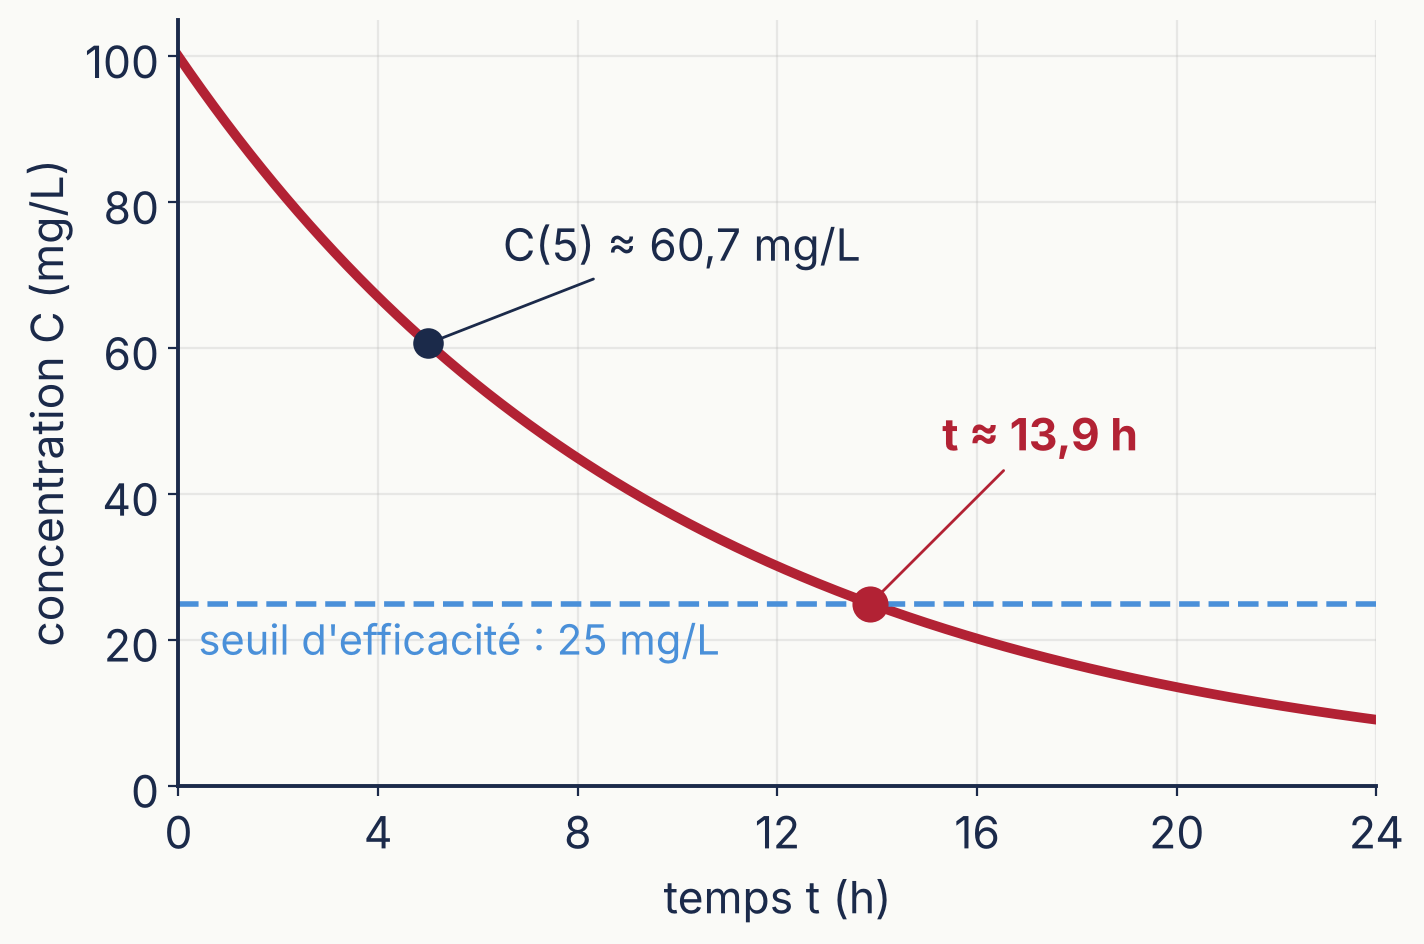

In [2]:
C0 = 100.0          # concentration initiale (mg/L)
k = 0.1             # constante d'élimination (h^-1)


def C(t):
    return C0 * np.exp(-k * t)


C5 = C(5.0)                         # concentration après 5 h
t_demi = math.log(2) / k            # demi-vie : C(t½) = C0/2
t_25 = math.log(C0 / 25) / k        # 100·e^(−0,1 t) = 25  ==>  t = ln 4 / 0,1

# Vérification de la dérivée : C'(t) = −k·C(t) (différences finies)
t = np.linspace(0, 24, 2001)
assert np.max(np.abs(np.gradient(C(t), t)[5:-5] + k * C(t)[5:-5])) < 1e-3
# Après n demi-vies : C = C0 / 2^n
for n in range(4):
    assert abs(C(n * t_demi) - C0 / 2**n) < 1e-9

fig, ax = nouvelle_figure(7.4, 5.0)
ax.plot(t, C(t), color=RED, lw=3.5)
ax.axhline(25, color=BLUE, ls="--", lw=2)
ax.text(0.4, 18, "seuil d'efficacité : 25 mg/L", color=BLUE, fontsize=15)
ax.plot([5], [C5], "o", color=NAVY, ms=10)
ax.annotate(f"C(5) ≈ {fr(C5, 1)} mg/L", (5, C5), (6.5, 72), arrowprops=dict(arrowstyle="-", color=NAVY))
ax.plot([t_25], [25], "o", color=RED, ms=12)
ax.annotate(f"t ≈ {fr(t_25, 1)} h", (t_25, 25), (15.3, 46), color=RED, fontweight="bold",
            arrowprops=dict(arrowstyle="-", color=RED))
ax.set(xlim=(0, 24), ylim=(0, 105), xlabel="temps t (h)", ylabel="concentration C (mg/L)")
ax.set_xticks(range(0, 25, 4))
enregistrer(fig, ax, "1_concentration.png")

### 2. PRISES RÉPÉTÉES — un comprimé toutes les τ heures

Juste après la n-ième prise : C_{n+1} = q·C_n + 100,  avec q = e^(−kτ)
Somme géométrique : C_n = 100·(1 − q^n)/(1 − q)  -->  100/(1 − q)

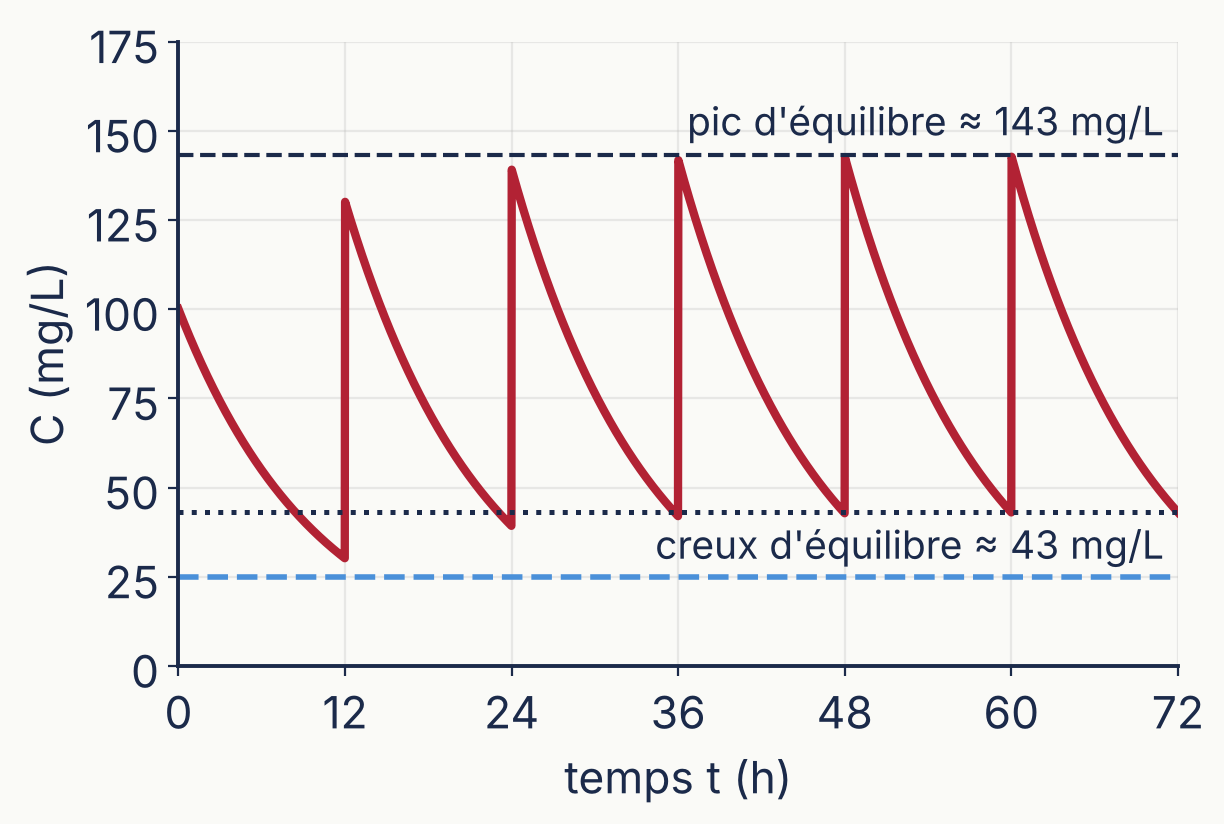

In [3]:
tau = 12.0
q = math.exp(-k * tau)
pics = [C0]
for _ in range(9):
    pics.append(q * pics[-1] + C0)                        # récurrence
for n, c in enumerate(pics, start=1):
    assert abs(c - C0 * (1 - q**n) / (1 - q)) < 1e-9      # formule fermée
pic_eq = C0 / (1 - q)              # pic d'équilibre
creux_eq = q * pic_eq              # creux d'équilibre (juste avant une prise)

T = np.linspace(0, 72, 3000)
# principe de superposition : chaque comprimé ajoute sa propre exponentielle
C_rep = sum(C0 * np.exp(-k * (T - j * tau)) * (T >= j * tau) for j in range(6))
fig, ax = nouvelle_figure(6.4, 4.4)
ax.plot(T, C_rep, color=RED, lw=3)
ax.axhline(pic_eq, color=NAVY, ls="--", lw=1.5)
ax.axhline(creux_eq, color=NAVY, ls=":", lw=1.8)
ax.axhline(25, color=BLUE, ls="--", lw=2)
ax.text(71, pic_eq + 3, f"pic d'équilibre ≈ {pic_eq:.0f} mg/L", ha="right", va="bottom", fontsize=14)
ax.text(71, creux_eq - 2.5, f"creux d'équilibre ≈ {creux_eq:.0f} mg/L", ha="right", va="top", fontsize=14)
ax.set(xlim=(0, 72), ylim=(0, 175), xlabel="temps t (h)", ylabel="C (mg/L)")
ax.set_xticks(range(0, 73, 12))
enregistrer(fig, ax, "2_prises_repetees.png")

# Cas de la présentation : une prise à chaque demi-vie (τ = t½, donc q = 1/2)
#   P_{n+1} = P_n / 2 + 100  -->  limite 200 ;  P_n = 200·(1 − 1/2^n)
q_demi = math.exp(-k * t_demi)
assert abs(q_demi - 0.5) < 1e-12
pics_demi = [C0]
for _ in range(9):
    pics_demi.append(q_demi * pics_demi[-1] + C0)
for n, c in enumerate(pics_demi, start=1):
    assert abs(c - 200 * (1 - 0.5**n)) < 1e-9          # somme géométrique 1 + 1/2 + ... + 1/2^(n-1)

### 3. MACHINE LEARNING — retrouver k à partir de mesures (régression linéaire)

ln C = ln C0 − k·t   est une droite  y = a·t + b   (a = −k, b = ln C0)
On minimise E(a, b) = (1/N)·Σ (y_i − (a·t_i + b))²   (moindres carrés)

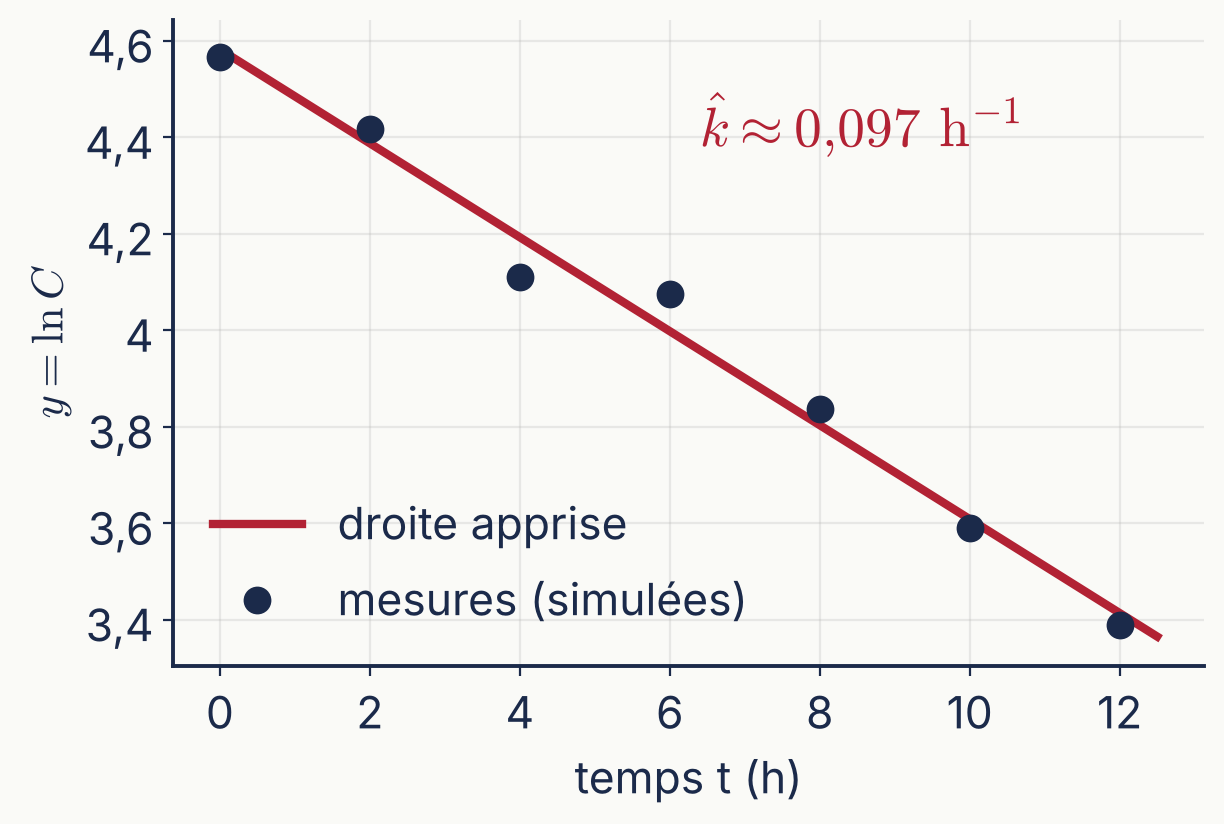

In [4]:
rng = np.random.default_rng(2026)                 # graine fixée : résultats reproductibles
t_mes = np.arange(0, 13, 2.0)                     # 7 mesures, toutes les 2 h
C_mes = C(t_mes) * np.exp(rng.normal(0, 0.05, t_mes.size))   # bruit de mesure ≈ 5 %
y_mes = np.log(C_mes)

a_mc, b_mc = np.polyfit(t_mes, y_mes, 1)          # solution exacte des moindres carrés
k_estime = -a_mc

fig, ax = nouvelle_figure()
tt = np.linspace(0, 12.5, 100)
ax.plot(tt, a_mc * tt + b_mc, color=RED, lw=3, label="droite apprise")
ax.plot(t_mes, y_mes, "o", color=NAVY, ms=9, label="mesures (simulées)")
ax.text(6.4, 4.38, rf"$\hat{{k}} \approx {fr(k_estime, 3).replace(',', '{,}')}\ \mathrm{{h}}^{{-1}}$", color=RED, fontsize=20)
ax.set(xlabel="temps t (h)", ylabel=r"$y = \ln C$")
ax.legend(frameon=False, loc="lower left")
enregistrer(fig, ax, "3_regression.png")

### 4. DESCENTE DE GRADIENT — comment un algorithme trouve ce minimum

a <- a − η·∂E/∂a ,  b <- b − η·∂E/∂b
∂E/∂a = (2/N)·Σ t_i·(a·t_i + b − y_i) ,  ∂E/∂b = (2/N)·Σ (a·t_i + b − y_i)

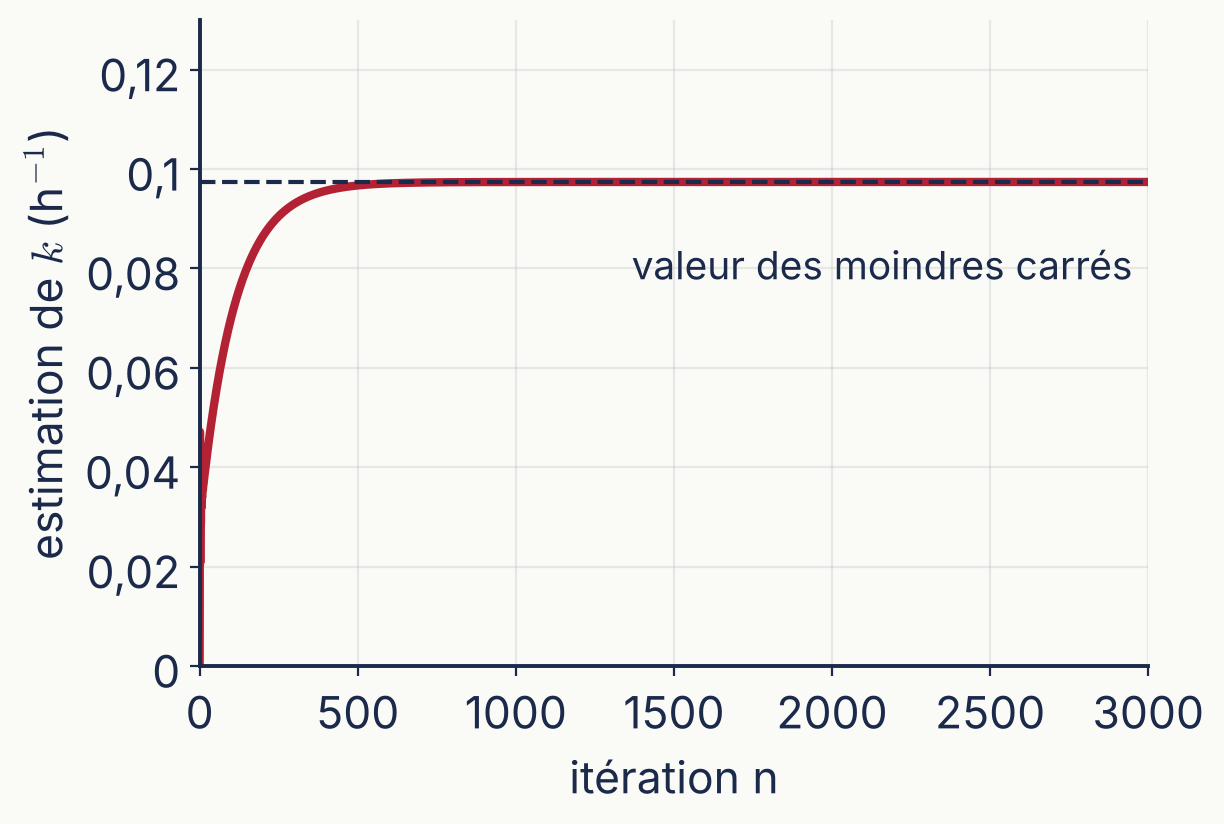

In [5]:
a, b = 0.0, 4.0            # point de départ
eta = 0.015                # pas d'apprentissage
historique = []
for iteration in range(3001):
    residu = a * t_mes + b - y_mes
    historique.append((iteration, -a))
    a -= eta * 2 * np.mean(residu * t_mes)
    b -= eta * 2 * np.mean(residu)
k_gd = -a
assert abs(k_gd - k_estime) < 1e-6                 # même résultat que les moindres carrés

H = np.array(historique)
fig, ax = nouvelle_figure()
ax.plot(H[:, 0], H[:, 1], color=RED, lw=3)
ax.axhline(k_estime, color=NAVY, ls="--", lw=1.5)
ax.text(2950, k_estime - 0.012, "valeur des moindres carrés", ha="right", va="top", fontsize=14)
ax.set(xlim=(0, 3000), ylim=(0, 0.13), xlabel="itération n", ylabel=r"estimation de $k$ (h$^{-1}$)")
enregistrer(fig, ax, "4_descente_gradient.png")

### 5. LOI DE POISEUILLE — Q = π·r⁴·ΔP / (8·μ·L)

À pression égale : Q/Q0 = (r/r0)⁴
Sensibilité (dérivée) : ΔQ/Q ≈ 4·Δr/r

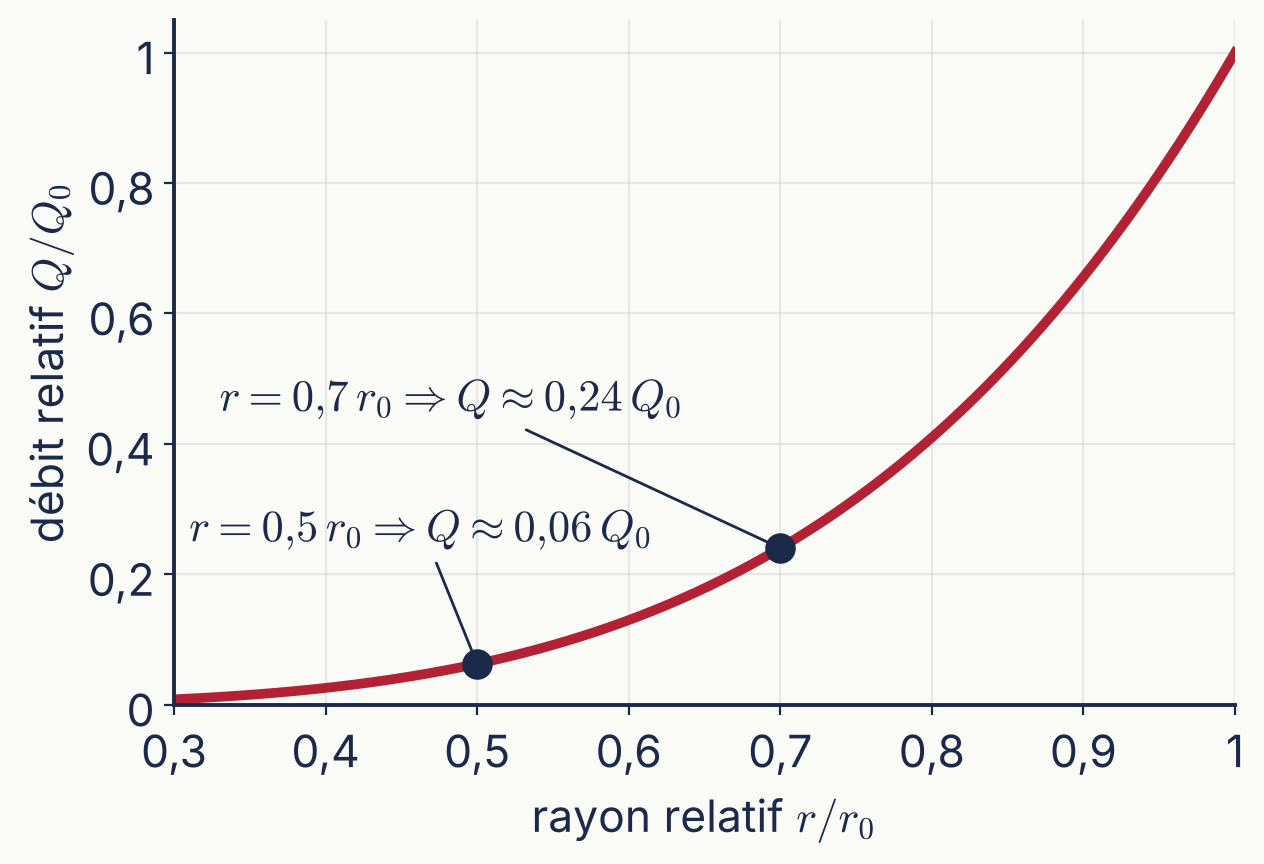

In [6]:
facteur_moitie = 2**4                  # rayon divisé par 2 -> résistance × 16
debit_70 = 0.7**4                      # rayon à 70 % -> débit × 0,2401
division_70 = 1 / debit_70             # ≈ 4,2
sensibilite = {p: (100 * 4 * p / 100, 100 * (1 - (1 - p / 100) ** 4)) for p in (1, 5, 10)}

x = np.linspace(0.3, 1, 300)
fig, ax = nouvelle_figure(6.6, 4.6)
ax.plot(x, x**4, color=RED, lw=3.5)
for r_, texte, pos in [(0.7, r"$r=0{,}7\,r_0 \Rightarrow Q\approx 0{,}24\,Q_0$", (0.33, 0.45)),
                       (0.5, r"$r=0{,}5\,r_0 \Rightarrow Q\approx 0{,}06\,Q_0$", (0.31, 0.25))]:
    ax.plot([r_], [r_**4], "o", color=NAVY, ms=10)
    ax.annotate(texte, (r_, r_**4), pos, arrowprops=dict(arrowstyle="-", color=NAVY))
ax.set(xlim=(0.3, 1), ylim=(0, 1.05), xlabel=r"rayon relatif $r/r_0$", ylabel=r"débit relatif $Q/Q_0$")
enregistrer(fig, ax, "5_poiseuille_r4.png")

### 6. STENT — cellule en losange de côté L, angle d'ouverture θ, n cellules sur le tour

largeur w = 2L·sin(θ/2) ,  hauteur h = 2L·cos(θ/2) ,  π·d = n·w
Pythagore : (w/2)² + (h/2)² = L²   ==>   h(d) = √(4L² − (π·d/n)²)

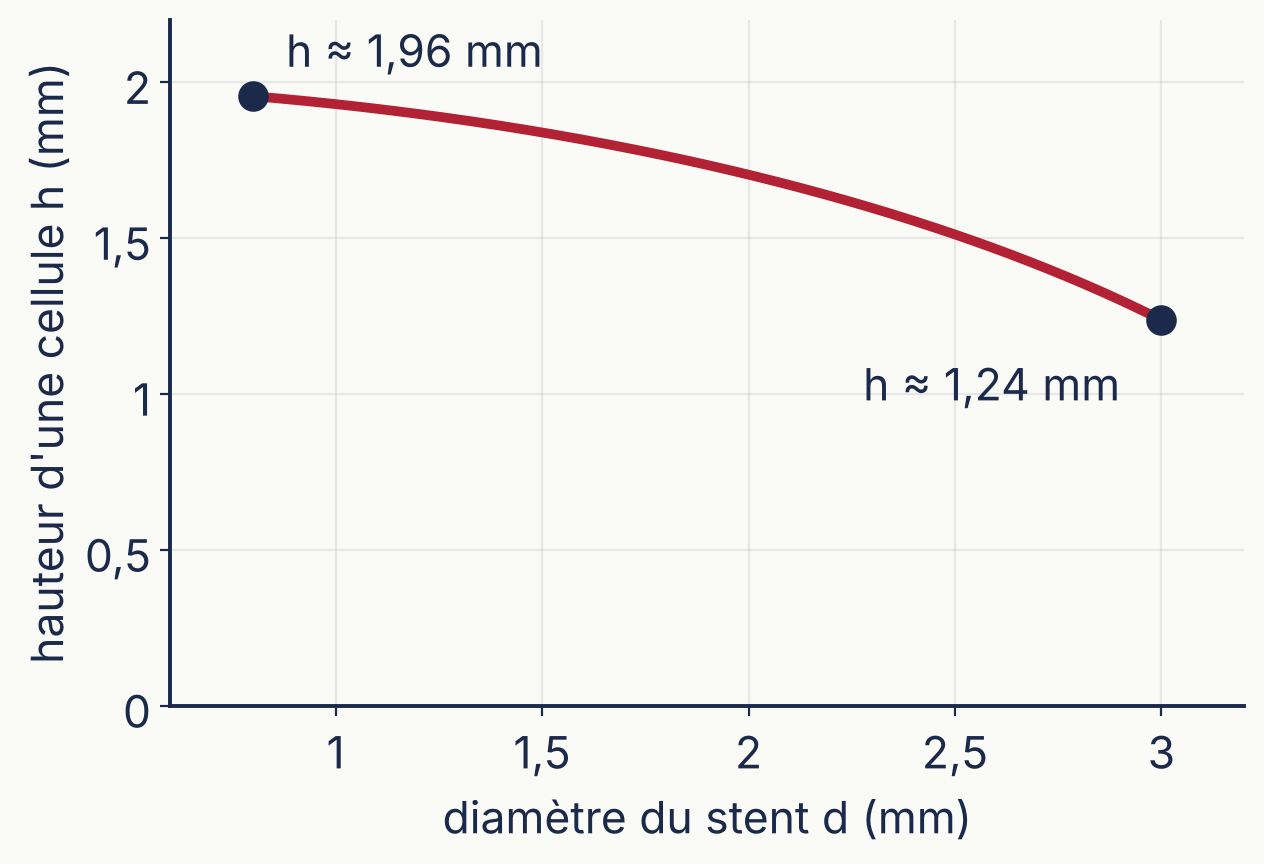

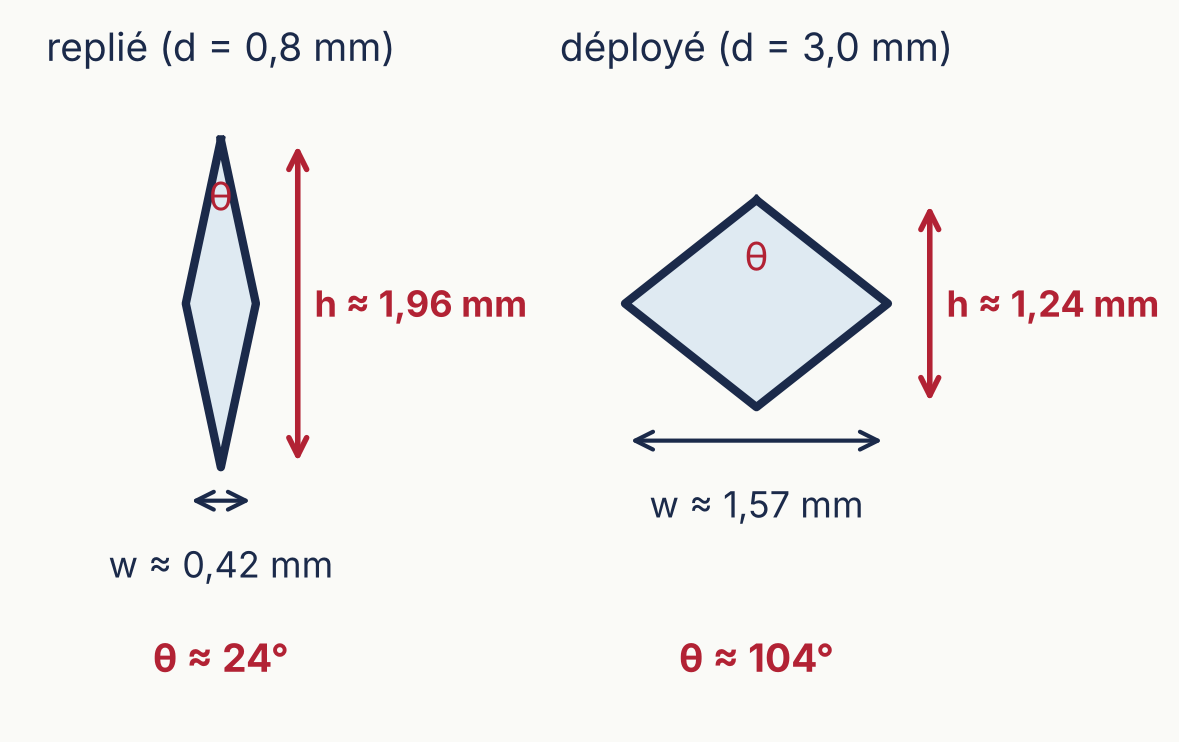

In [7]:
n_cell, L = 6, 1.0


def cellule(d):
    s = math.pi * d / (2 * n_cell * L)          # sin(θ/2)
    demi_angle = math.asin(s)
    theta = 2 * math.degrees(demi_angle)
    w = 2 * L * s
    h = 2 * L * math.cos(demi_angle)
    assert abs(h - math.sqrt(4 * L**2 - (math.pi * d / n_cell) ** 2)) < 1e-12   # Pythagore
    return theta, w, h


D_REPLIE, D_DEPLOYE = 0.8, 3.0                   # brevet US 9 510 960 : serti à 0,8 mm, déployé à 3,0 mm
stent = {d: cellule(d) for d in (D_REPLIE, D_DEPLOYE)}
rapport_h = stent[D_DEPLOYE][2] / stent[D_REPLIE][2]   # ≈ 0,63  -> −37 % de hauteur
d_max = 2 * n_cell * L / math.pi                 # ouverture maximale (losanges aplatis) ≈ 3,82 mm

dd = np.linspace(D_REPLIE, D_DEPLOYE, 200)
fig, ax = nouvelle_figure(6.6, 4.6)
ax.plot(dd, np.sqrt(4 * L**2 - (np.pi * dd / n_cell) ** 2), color=RED, lw=3.5)
for d in (D_REPLIE, D_DEPLOYE):
    h = stent[d][2]
    ax.plot([d], [h], "o", color=NAVY, ms=10)
    ax.text(d + 0.08 if d < 2 else d - 0.1, h + 0.06 if d < 2 else h - 0.12, f"h ≈ {fr(h)} mm",
            ha="left" if d < 2 else "right", va="bottom" if d < 2 else "top")
ax.set(xlim=(0.6, 3.2), ylim=(0, 2.2), xlabel="diamètre du stent d (mm)", ylabel="hauteur d'une cellule h (mm)")
enregistrer(fig, ax, "6_stent_hauteur.png")

# Une cellule repliée et déployée, à la même échelle (figure du rapport)
fig, ax = plt.subplots(figsize=(7.6, 4.0))
fig.patch.set_facecolor(BG); ax.set_facecolor(BG); ax.set_aspect("equal"); ax.axis("off")
for x0, d, titre in [(0.0, D_REPLIE, "replié"), (3.2, D_DEPLOYE, "déployé")]:
    th, w, h = stent[d]
    X = [x0, x0 + w / 2, x0, x0 - w / 2, x0]
    Y = [h / 2, 0, -h / 2, 0, h / 2]
    ax.fill(X, Y, color=BLUE, alpha=0.15)
    ax.plot(X, Y, color=NAVY, lw=3)
    ax.text(x0, 1.45, f"{titre} (d = {fr(d, 1)} mm)", ha="center", fontsize=14)
    ax.annotate("", (x0 + w / 2 + 0.25, h / 2), (x0 + w / 2 + 0.25, -h / 2), arrowprops=dict(arrowstyle="<->", color=RED, lw=2))
    ax.text(x0 + w / 2 + 0.35, 0, f"h ≈ {fr(h)} mm", color=RED, va="center", fontsize=13, fontweight="bold")
    ax.annotate("", (x0 - w / 2, -h / 2 - 0.2), (x0 + w / 2, -h / 2 - 0.2), arrowprops=dict(arrowstyle="<->", color=NAVY, lw=1.5))
    ax.text(x0, -h / 2 - 0.45, f"w ≈ {fr(w)} mm", ha="center", va="top", fontsize=13)
    ax.text(x0, h / 2 - 0.42, "θ", ha="center", color=RED, fontsize=14)
    ax.text(x0, -2.2, f"θ ≈ {th:.0f}°", ha="center", color=RED, fontsize=14, fontweight="bold")
ax.set(xlim=(-1.2, 5.6), ylim=(-2.5, 1.7))
fig.tight_layout()
fig.savefig(os.path.join(OUT, "6b_losanges.png"), dpi=300, facecolor=BG)
plt.show()

### 7. RÉSEAU DE NEURONES « INFORMÉ PAR L'ÉQUATION » (idée des PINN, Raissi et al. 2019)

Réseau : C_θ(t) = 100·( Σ_j v_j·tanh(w_j·t/24 + b_j) + c ),  8 neurones
Réseau A (données seules) : minimise l'erreur sur les mesures.
Réseau B (informé)        : erreur sur les mesures + erreur sur l'équation
dC/dt + k·C = 0, et apprend k en même temps.
Mesures : seulement 5 points sur [0 ; 4] h ; on regarde la prédiction jusqu'à 24 h.

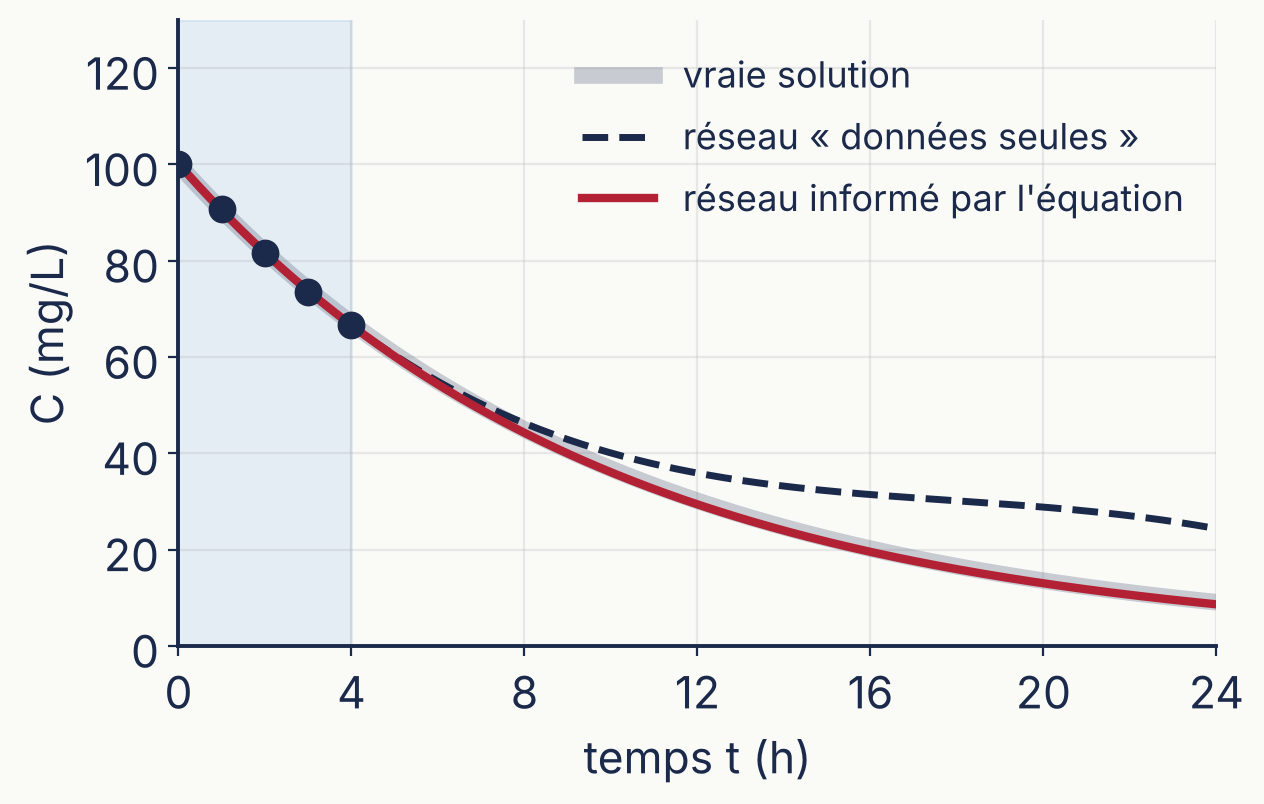

In [8]:
rng = np.random.default_rng(7)
t_d = np.array([0, 1, 2, 3, 4.0])
C_d = C(t_d) * (1 + rng.normal(0, 0.01, t_d.size))      # bruit ≈ 1 %
t_eq = np.linspace(0, 24, 49)                            # points où l'on impose l'équation
NH = 8                                                   # neurones cachés


def reseau(p, t):
    """Renvoie C_θ(t) et sa dérivée exacte dC_θ/dt."""
    w, b, v, c = p[:NH], p[NH:2 * NH], p[2 * NH:3 * NH], p[3 * NH]
    z = np.tanh(w * t[:, None] / 24 + b)
    u = z @ v + c
    du = ((1 - z**2) * w) @ v / 24          # dérivée de tanh : 1 − tanh²
    return 100 * u, 100 * du


def perte_donnees(p):
    u, _ = reseau(p, t_d)
    return np.mean(((u - C_d) / 100) ** 2)


def perte_informee(p):
    k_appris = p[-1]
    u, du = reseau(p[:-1], t_eq)
    residu = (du + k_appris * u) / 100 * 24          # résidu de l'équation (mis à l'échelle)
    return perte_donnees(p[:-1]) + 0.1 * np.mean(residu**2)


def entrainer(perte, avec_k):
    meilleur = None
    for graine in range(8):                           # plusieurs départs aléatoires
        p0 = np.random.default_rng(graine).normal(0, 1, 3 * NH + 1)
        if avec_k:
            p0 = np.append(p0, 0.5)                   # k inconnu : on part de 0,5 h^-1
        res = minimize(perte, p0, method="L-BFGS-B", options={"maxiter": 5000})
        if meilleur is None or res.fun < meilleur.fun:
            meilleur = res
    return meilleur.x


p_A = entrainer(perte_donnees, avec_k=False)
p_B = entrainer(perte_informee, avec_k=True)
k_pinn = p_B[-1]
tp = np.linspace(0, 24, 300)
C_A, _ = reseau(p_A, tp)
C_B, _ = reseau(p_B[:-1], tp)
erreur_A_24 = C_A[-1] - C(24.0)
erreur_B_max = np.max(np.abs(C_B - C(tp)))

fig, ax = nouvelle_figure(6.6, 4.3)
ax.axvspan(0, 4, color=BLUE, alpha=0.12)
ax.plot(tp, C(tp), color=GREY, lw=6, alpha=0.35, label="vraie solution")
ax.plot(tp, C_A, color=NAVY, lw=2.5, ls="--", label="réseau « données seules »")
ax.plot(tp, C_B, color=RED, lw=3, label="réseau informé par l'équation")
ax.plot(t_d, C_d, "o", color=NAVY, ms=9)
ax.set(xlim=(0, 24), ylim=(0, 130), xlabel="temps t (h)", ylabel="C (mg/L)")
ax.set_xticks(range(0, 25, 4))
ax.legend(frameon=False, fontsize=13, loc="upper right")
enregistrer(fig, ax, "7_reseau_informe.png")

### RÉCAPITULATIF DES VALEURS (celles écrites sur les diapos)

In [9]:
print("=== 1. Médicament ===")
print(f"C(5)            = {fr(C5, 2)} mg/L        (diapo : ≈ 60,7)")
print(f"demi-vie        = {fr(t_demi, 2)} h           (diapo : ≈ 6,9 h)")
print(f"C < 25 mg/L à t = {fr(t_25, 2)} h          (diapo : ≈ 13,9 h = 2 demi-vies)")
print("=== 2. Prises répétées ===")
print("une prise à chaque demi-vie (présentation) : " + " ; ".join(fr(c, 2) for c in pics_demi[:6]) + " mg/L -> limite 200")
print("--- variante : une prise toutes les 12 h ---")
print(f"q = e^(-1,2)    = {fr(q, 4)}")
print("pics successifs : " + " ; ".join(fr(c, 1) for c in pics[:5]) + " mg/L")
print(f"pic d'équilibre = {fr(pic_eq, 1)} mg/L ; creux = {fr(creux_eq, 1)} mg/L")
print("=== 3-4. Apprentissage de k ===")
print("mesures simulées : " + " ; ".join(fr(c, 1) for c in C_mes) + " mg/L")
print(f"k (moindres carrés)     = {fr(k_estime, 4)} h^-1   (vraie valeur 0,1)")
print(f"k (descente de gradient) = {fr(k_gd, 4)} h^-1   après 3000 itérations")
print("=== 5. Poiseuille ===")
print(f"rayon ÷ 2 -> résistance × {facteur_moitie}")
print(f"0,7^4 = {fr(debit_70, 4)} -> débit divisé par {fr(division_70, 2)}")
for p, (approx, exact) in sensibilite.items():
    print(f"rayon −{p} % -> débit −{fr(approx, 0)} % (approx. ×4) / −{fr(exact, 1)} % (exact)")
print("=== 6. Stent (L = 1 mm, n = 6) ===")
for d, (th, w, h) in stent.items():
    print(f"d = {fr(d, 1)} mm : tour = {fr(math.pi * d)} mm, θ ≈ {fr(th, 1)}°, w ≈ {fr(w)} mm, h ≈ {fr(h)} mm")
print(f"h(3,0)/h(0,8) = {fr(rapport_h, 3)} -> perte de hauteur ≈ {(1 - rapport_h) * 100:.0f} %")
print(f"diamètre maximal 2nL/π = {fr(d_max)} mm")
print("=== 7. Réseau informé par l'équation ===")
print(f"k appris = {fr(k_pinn, 3)} h^-1 ; erreur max sur 24 h = {fr(erreur_B_max, 2)} mg/L")
print(f"réseau « données seules » : erreur à 24 h = {fr(erreur_A_24, 1)} mg/L")
print(f"\nGraphiques enregistrés dans le dossier « {os.path.normpath(OUT)} ».")

=== 1. Médicament ===
C(5)            = 60,65 mg/L        (diapo : ≈ 60,7)
demi-vie        = 6,93 h           (diapo : ≈ 6,9 h)
C < 25 mg/L à t = 13,86 h          (diapo : ≈ 13,9 h = 2 demi-vies)
=== 2. Prises répétées ===
une prise à chaque demi-vie (présentation) : 100,00 ; 150,00 ; 175,00 ; 187,50 ; 193,75 ; 196,88 mg/L -> limite 200
--- variante : une prise toutes les 12 h ---
q = e^(-1,2)    = 0,3012
pics successifs : 100,0 ; 130,1 ; 139,2 ; 141,9 ; 142,7 mg/L
pic d'équilibre = 143,1 mg/L ; creux = 43,1 mg/L
=== 3-4. Apprentissage de k ===
mesures simulées : 96,1 ; 82,9 ; 61,0 ; 58,8 ; 46,4 ; 36,3 ; 29,7 mg/L
k (moindres carrés)     = 0,0974 h^-1   (vraie valeur 0,1)
k (descente de gradient) = 0,0974 h^-1   après 3000 itérations
=== 5. Poiseuille ===
rayon ÷ 2 -> résistance × 16
0,7^4 = 0,2401 -> débit divisé par 4,16
rayon −1 % -> débit −4 % (approx. ×4) / −3,9 % (exact)
rayon −5 % -> débit −20 % (approx. ×4) / −18,5 % (exact)
rayon −10 % -> débit −40 % (approx. ×4) / −34,4 % (ex

## Partie B — Vraies données (théophylline)

Les mathématiques au service du cœur — partie « vraies données »
Fête de la Science 2026 — Bilel Charfi (ESPRIT)

Données : jeu « Theoph » (12 volontaires, théophylline par voie orale, 11 prélèvements
sur 25 h). Source : Boeckmann, Sheiner et Beal (1994), NONMEM Users Guide, Part V,
UCSF ; distribué avec le logiciel R (package datasets). Fichier : data/theoph.csv.

Ce script :
    R1. affiche les mesures du sujet 11 (celui de la présentation) ;
    R2. montre que ln C est presque une droite pendant la descente, et estime k
        par deux points puis par les moindres carrés ;
    R3. superpose le modèle C(t) = C0·e^(−kt) aux mesures ;
    R4. estime k et la demi-vie pour les 12 patients (variabilité) ;
    R5. ajuste un modèle plus large, à deux phases (absorption + élimination),
        qui explique aussi la montée ;
    R6. compare, sur des patients « nouveaux », ce modèle mathématique à deux
        méthodes d'apprentissage automatique (validation croisée patient par patient).


In [10]:
import math
import os

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.optimize import curve_fit
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RED, NAVY, BLUE, BG, GREY = "#B22234", "#1B2A4A", "#4A90D9", "#FAFAF7", "#6B768C"
plt.rcParams.update({
    "mathtext.fontset": "cm", "font.size": 15,
    "axes.edgecolor": NAVY, "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": NAVY, "ytick.color": NAVY,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 1.4,
})
ICI = os.getcwd()   # le notebook est à la racine du dépôt
DATA = os.path.join(ICI, "data", "theoph.csv")
OUT = os.path.join(ICI, "figures")
os.makedirs(OUT, exist_ok=True)


def fr(x, nd=2):
    return f"{x:.{nd}f}".replace(".", ",")


def nouvelle_figure(w=6.6, h=4.4):
    fig, ax = plt.subplots(figsize=(w, h))
    fig.patch.set_facecolor(BG)
    ax.set_facecolor(BG)
    ax.grid(alpha=0.25)
    return fig, ax


def enregistrer(fig, ax, nom):
    f = FuncFormatter(lambda v, pos: f"{v:g}".replace(".", ","))
    ax.xaxis.set_major_formatter(f)
    ax.yaxis.set_major_formatter(f)
    fig.tight_layout()
    fig.savefig(os.path.join(OUT, nom), dpi=300, facecolor=BG)
    plt.show()

### Lecture des données

In [11]:
df = pd.read_csv(DATA)            # colonnes : Subject, Wt (kg), Dose (mg/kg), Time (h), conc (mg/L)
assert len(df) == 132 and df.Subject.nunique() == 12
S11 = df[df.Subject == 11].sort_values("Time")
t11, c11 = S11.Time.to_numpy(), S11.conc.to_numpy()

### R1 — Les mesures du sujet 11

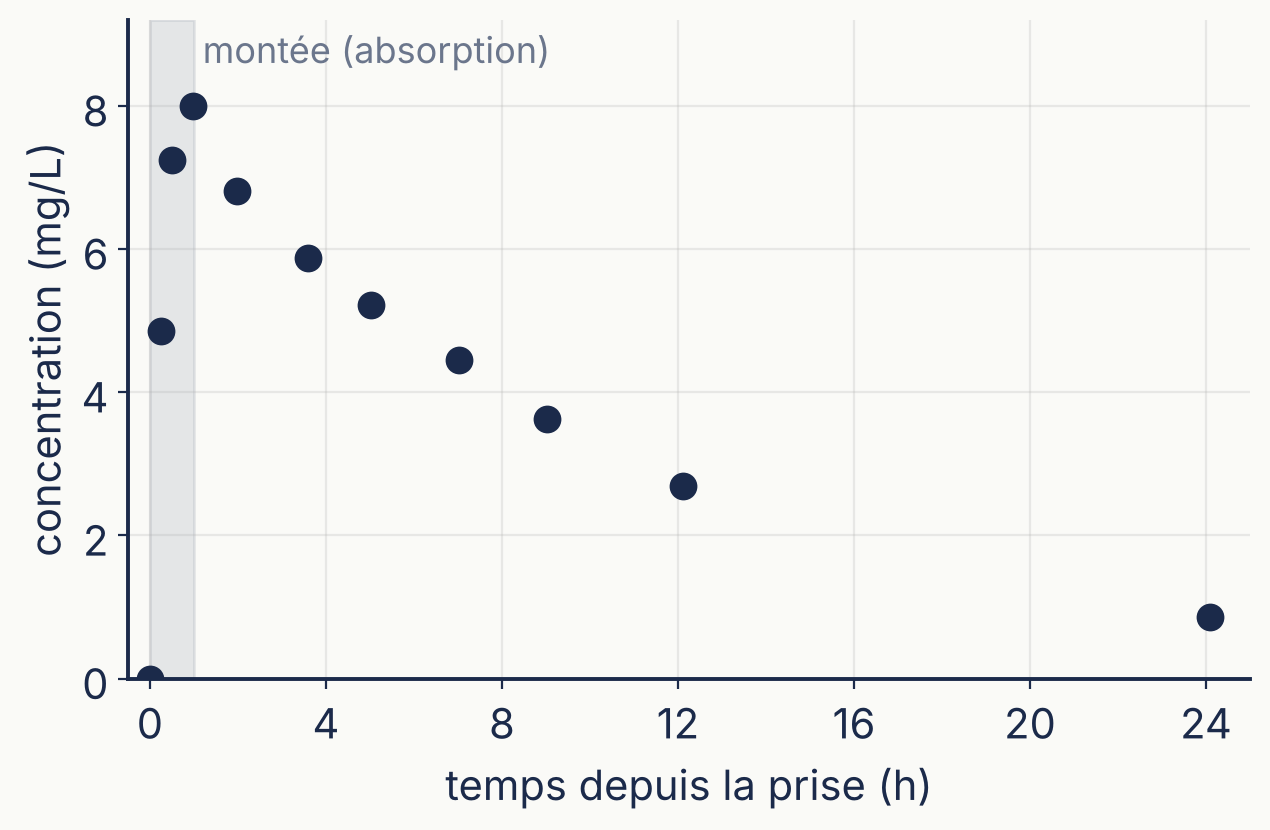

In [12]:
fig, ax = nouvelle_figure()
ax.axvspan(0, 1.0, color=GREY, alpha=0.15)
ax.text(1.2, 8.6, "montée (absorption)", fontsize=13, color=GREY)
ax.plot(t11, c11, "o", color=NAVY, ms=9)
ax.set(xlim=(-0.5, 25), ylim=(0, 9.2), xlabel="temps depuis la prise (h)", ylabel="concentration (mg/L)")
ax.set_xticks(range(0, 25, 4))
enregistrer(fig, ax, "R1_sujet11_mesures.png")

### R2 — Pendant la descente, ln C est presque une droite

ln C(t) = ln C0 − k·t   (si C(t) = C0·e^(−kt))

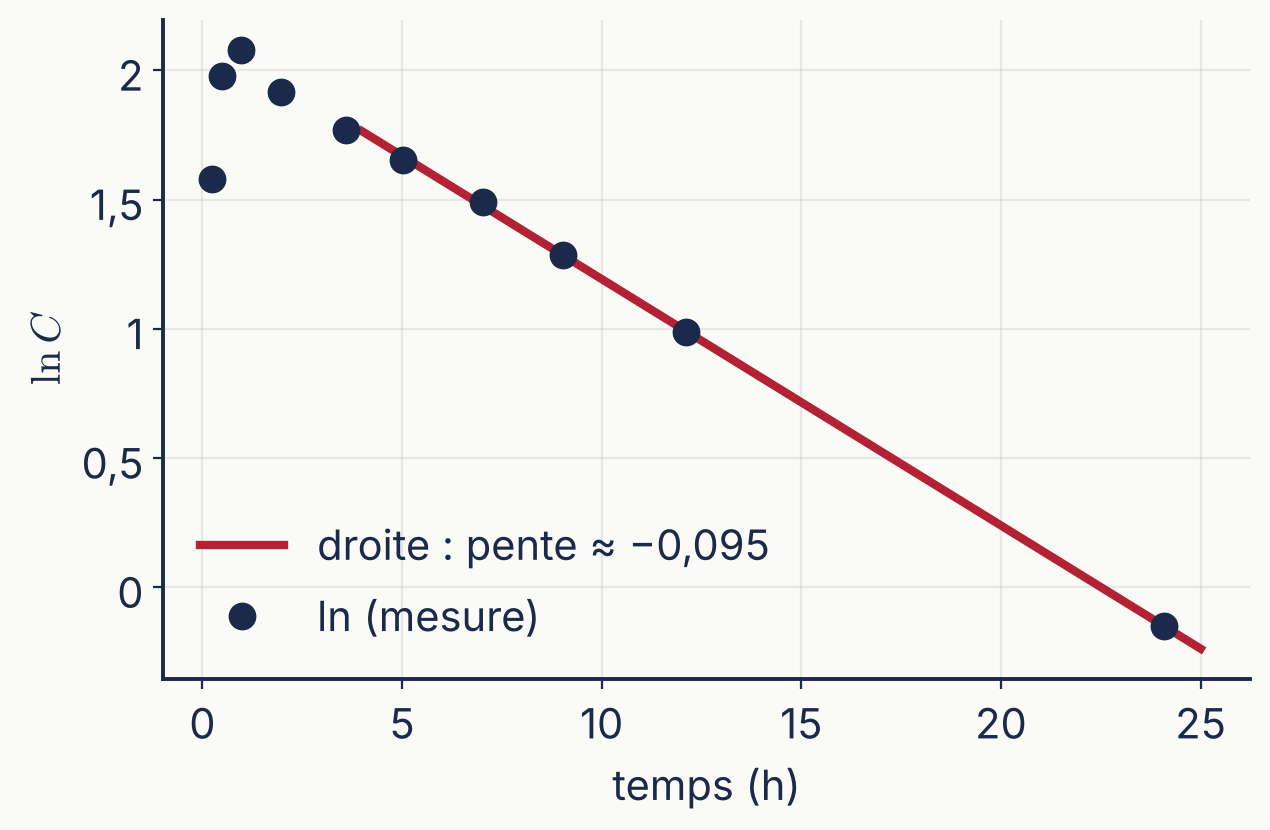

In [13]:
desc = t11 >= 5
a, b = np.polyfit(t11[desc], np.log(c11[desc]), 1)      # moindres carrés sur ln C
k11, C0_11 = -a, math.exp(b)
t_demi11 = math.log(2) / k11
k_2pts = math.log(5.22 / 2.69) / (12.12 - 5.02)          # méthode « deux points » de la présentation
r2 = np.corrcoef(t11[desc], np.log(c11[desc]))[0, 1] ** 2
assert round(k11, 3) == 0.095 and round(k_2pts, 3) == 0.093 and r2 > 0.999

fig, ax = nouvelle_figure()
tt = np.linspace(4, 25, 100)
ax.plot(tt, a * tt + b, color=RED, lw=3, label=f"droite : pente ≈ −{fr(k11, 3)}")
ax.plot(t11[c11 > 0], np.log(c11[c11 > 0]), "o", color=NAVY, ms=9, label="ln (mesure)")
ax.set(xlabel="temps (h)", ylabel=r"$\ln C$")
ax.legend(frameon=False, loc="lower left")
enregistrer(fig, ax, "R2_sujet11_log.png")

### R3 — Le modèle exponentiel face aux mesures

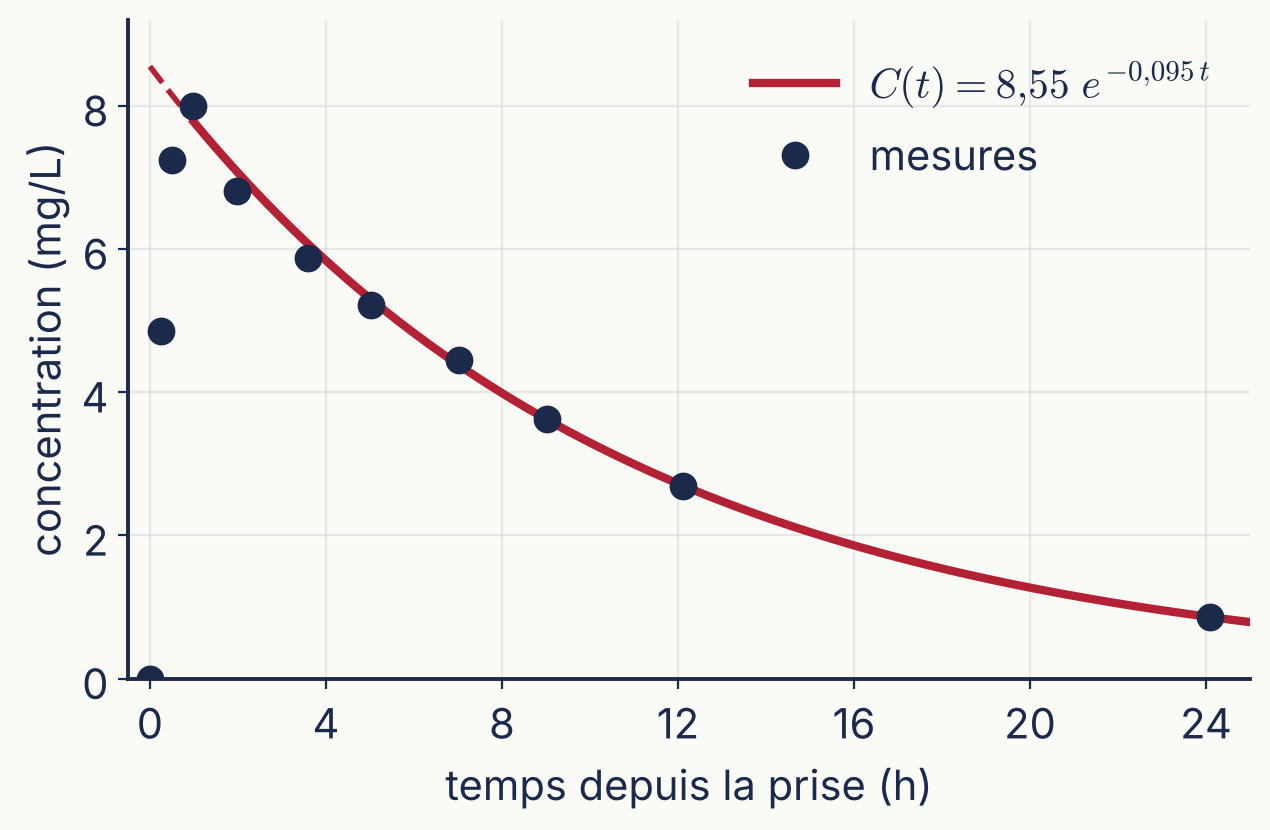

In [14]:
fig, ax = nouvelle_figure()
tt = np.linspace(1, 25, 300)
ax.plot(tt, C0_11 * np.exp(-k11 * tt), color=RED, lw=3, label=r"$C(t)=" + fr(C0_11).replace(",", "{,}") + r"\;e^{-" + fr(k11, 3).replace(",", "{,}") + r"\,t}$")
ax.plot(np.linspace(0, 1, 30), C0_11 * np.exp(-k11 * np.linspace(0, 1, 30)), color=RED, lw=2, ls="--")
ax.plot(t11, c11, "o", color=NAVY, ms=9, label="mesures")
ax.set(xlim=(-0.5, 25), ylim=(0, 9.2), xlabel="temps depuis la prise (h)", ylabel="concentration (mg/L)")
ax.set_xticks(range(0, 25, 4))
ax.legend(frameon=False)
enregistrer(fig, ax, "R3_sujet11_modele.png")

### R4 — Variabilité : k et demi-vie pour les 12 patients

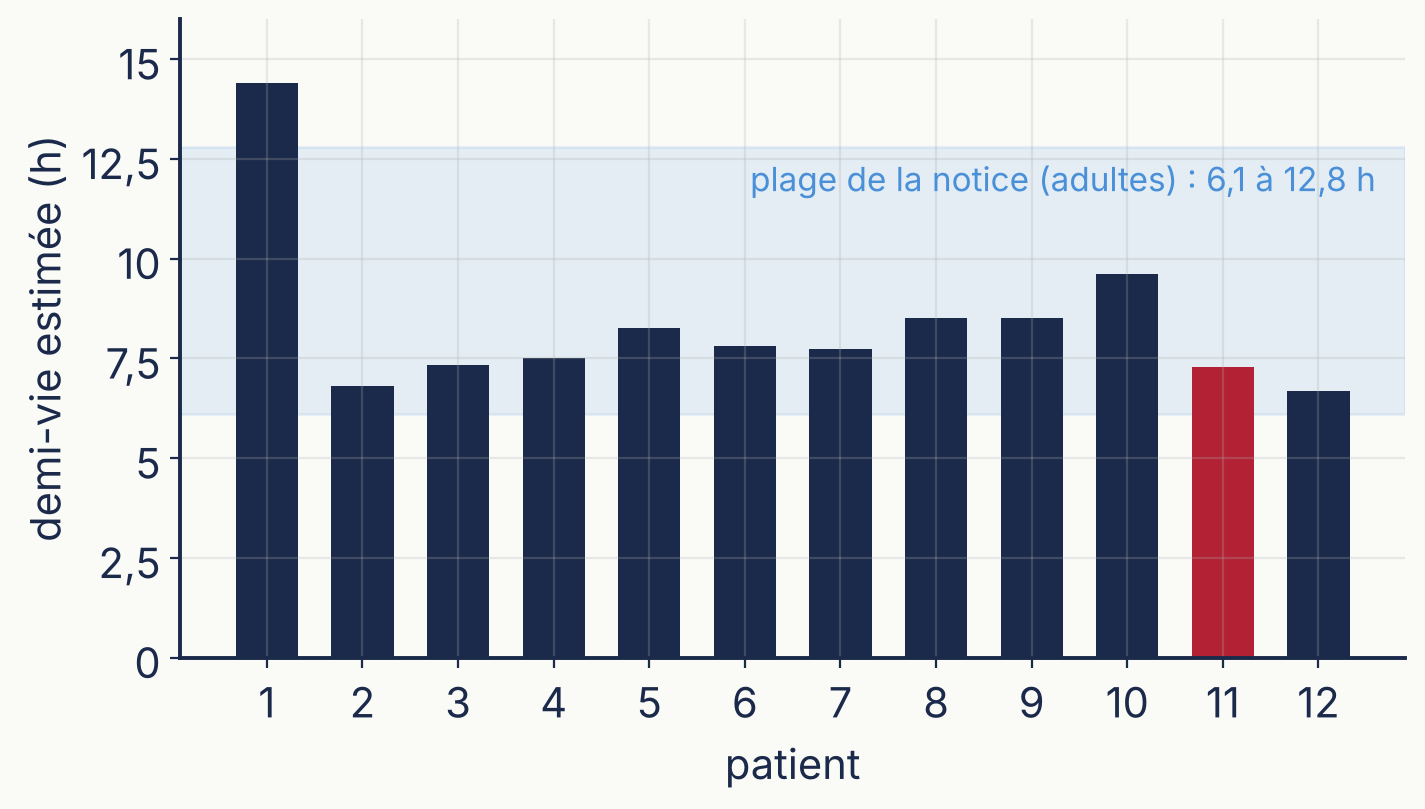

In [15]:
lignes = []
for s, g in df.groupby("Subject"):
    g = g.sort_values("Time")
    m = g.Time >= 5
    aa, bb = np.polyfit(g.Time[m], np.log(g.conc[m]), 1)
    lignes.append({"patient": int(s), "poids_kg": g.Wt.iloc[0], "dose_mg_kg": g.Dose.iloc[0],
                   "k_h-1": -aa, "demi_vie_h": math.log(2) / -aa, "Cmax": g.conc.max(),
                   "tmax_h": g.Time[g.conc.idxmax()]})
pop = pd.DataFrame(lignes)
pop.round(4).to_csv(os.path.join(OUT, "R4_parametres_12_patients.csv"), index=False)

fig, ax = nouvelle_figure(7.2, 4.4)
ax.axhspan(6.1, 12.8, color=BLUE, alpha=0.12)
ax.text(12.6, 12.5, "plage de la notice (adultes) : 6,1 à 12,8 h", ha="right", va="top", fontsize=12, color=BLUE)
couleurs = [RED if p == 11 else NAVY for p in pop.patient]
ax.bar(pop.patient, pop.demi_vie_h, color=couleurs, width=0.65)
ax.set(xticks=range(1, 13), ylim=(0, 16), xlabel="patient", ylabel="demi-vie estimée (h)")
enregistrer(fig, ax, "R4_demi_vies_12_patients.png")

### R5 — Un modèle plus large : absorption + élimination (modèle à un compartiment,

absorption d'ordre 1, « équation de Bateman ») :
C'(t) = ka·A(t)/V − k·C(t),  A(t) = D·e^(−ka t)   ==>
C(t) = D·ka / (V·(ka − k)) · (e^(−k t) − e^(−ka t))
D : dose (mg/kg), V : volume apparent (L/kg), ka : absorption (h^-1)

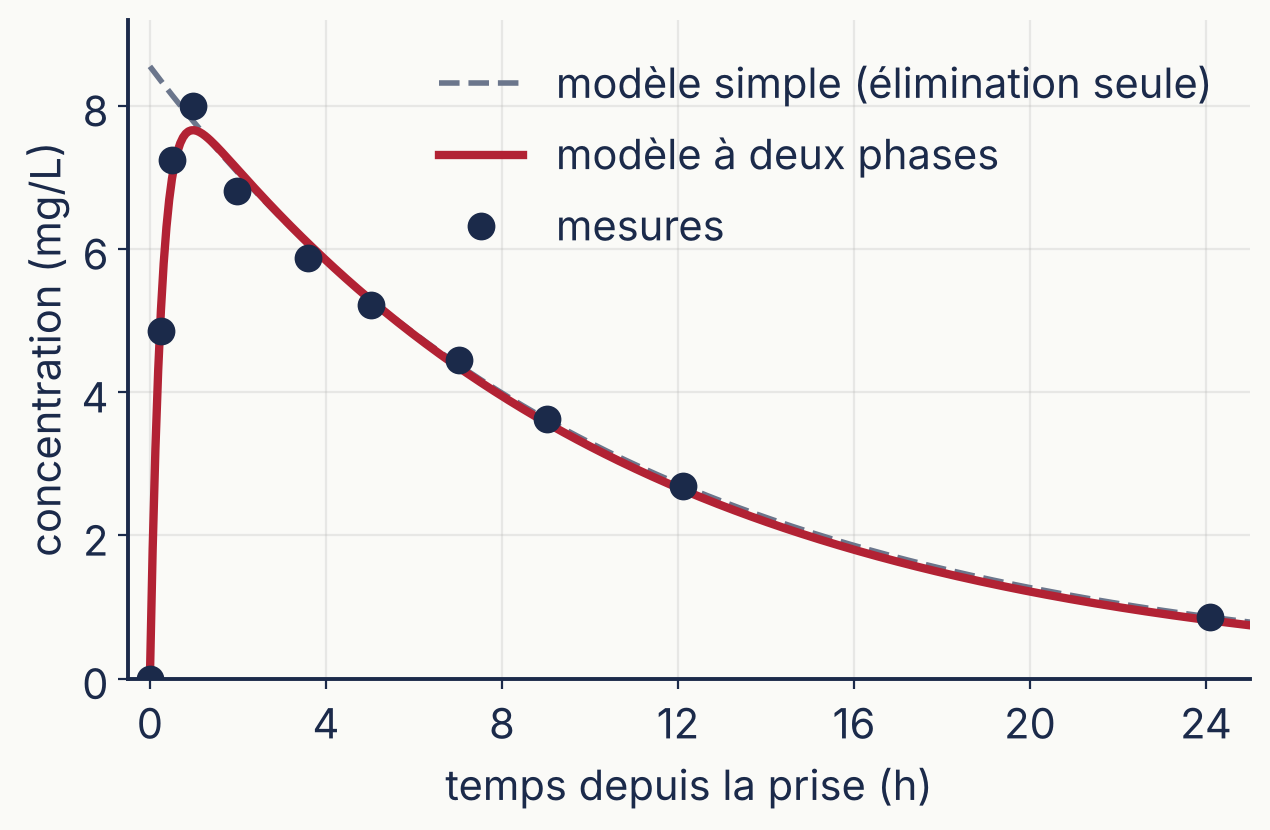

In [16]:
def bateman(t, ka, k, V, D):
    return D * ka / (V * (ka - k)) * (np.exp(-k * t) - np.exp(-ka * t))


def ajuster(g):
    D = g.Dose.iloc[0]
    f = lambda t, lka, lk, lV: bateman(t, math.exp(lka), math.exp(lk), math.exp(lV), D)
    p, _ = curve_fit(f, g.Time, g.conc, p0=[math.log(1.5), math.log(0.09), math.log(0.5)], maxfev=20000)
    return np.exp(p)


ka11, kb11, V11 = ajuster(S11)
fig, ax = nouvelle_figure()
tt = np.linspace(0, 25, 400)
ax.plot(tt, C0_11 * np.exp(-k11 * tt), color=GREY, lw=2, ls="--", label="modèle simple (élimination seule)")
ax.plot(tt, bateman(tt, ka11, kb11, V11, S11.Dose.iloc[0]), color=RED, lw=3, label="modèle à deux phases")
ax.plot(t11, c11, "o", color=NAVY, ms=9, label="mesures")
ax.set(xlim=(-0.5, 25), ylim=(0, 9.2), xlabel="temps depuis la prise (h)", ylabel="concentration (mg/L)")
ax.set_xticks(range(0, 25, 4))
ax.legend(frameon=False)
enregistrer(fig, ax, "R5_modele_deux_phases.png")

### R6 — Modèle mathématique ou apprentissage automatique ?

Validation croisée « un patient laissé de côté » : on apprend sur 11 patients
et on prédit toute la courbe du 12e, à partir de sa dose, de son poids et du temps.
- modèle de population : un seul jeu (ka, k, V) ajusté sur les 11 patients ;
- forêt aléatoire, k plus proches voisins et réseau de neurones sur (temps, dose, poids).

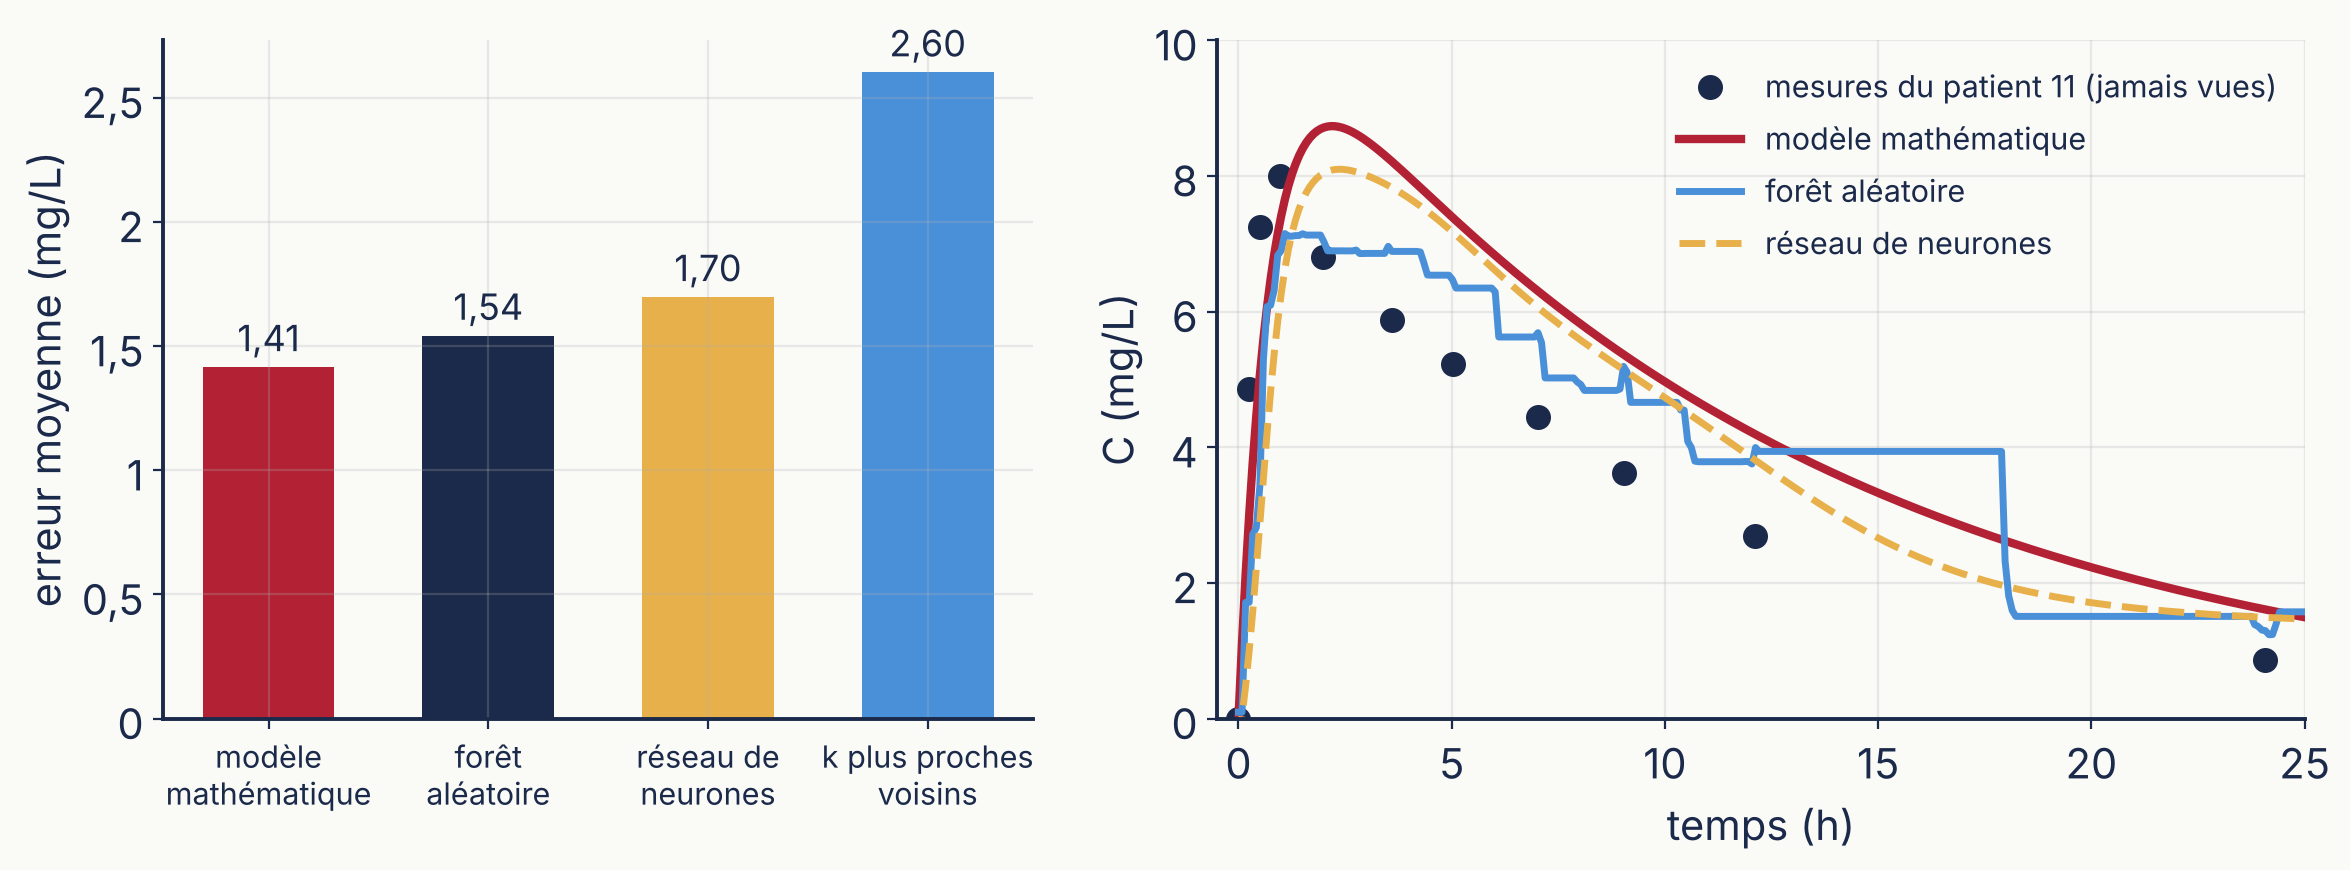

In [17]:
def ajuster_population(d):
    f = lambda X, lka, lk, lV: bateman(X[0], math.exp(lka), math.exp(lk), math.exp(lV), X[1])
    p, _ = curve_fit(f, (d.Time.to_numpy(), d.Dose.to_numpy()), d.conc.to_numpy(),
                     p0=[math.log(1.5), math.log(0.09), math.log(0.5)], maxfev=20000)
    return np.exp(p)


erreurs = {"modèle\nmathématique": [], "forêt\naléatoire": [], "réseau de\nneurones": [], "k plus proches\nvoisins": []}
pred_exemple = {}
for s in sorted(df.Subject.unique()):
    app, test = df[df.Subject != s], df[df.Subject == s].sort_values("Time")
    ka_p, k_p, V_p = ajuster_population(app)
    p_math = bateman(test.Time.to_numpy(), ka_p, k_p, V_p, test.Dose.iloc[0])
    X_app, X_test = app[["Time", "Dose", "Wt"]].to_numpy(), test[["Time", "Dose", "Wt"]].to_numpy()
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0).fit(X_app, app.conc)
    knn = KNeighborsRegressor(n_neighbors=5).fit(X_app / [24, 1, 30], app.conc)
    # réseau de neurones : 2 couches cachées de 16 neurones, entrées centrées-réduites
    mlp = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(16, 16), activation="tanh",
                        alpha=1e-3, max_iter=5000, random_state=0)).fit(X_app, app.conc)
    p_rf, p_knn, p_mlp = rf.predict(X_test), knn.predict(X_test / [24, 1, 30]), mlp.predict(X_test)
    for nom, p in zip(erreurs, (p_math, p_rf, p_mlp, p_knn)):
        erreurs[nom].append(math.sqrt(np.mean((p - test.conc.to_numpy()) ** 2)))
    if s == 11:
        tt = np.linspace(0, 25, 300)
        pred_exemple = {"t": tt, "math": bateman(tt, ka_p, k_p, V_p, test.Dose.iloc[0]),
                        "rf": rf.predict(np.c_[tt, np.full_like(tt, test.Dose.iloc[0]), np.full_like(tt, test.Wt.iloc[0])]),
                        "mlp": mlp.predict(np.c_[tt, np.full_like(tt, test.Dose.iloc[0]), np.full_like(tt, test.Wt.iloc[0])])}

rmse = {nom: float(np.mean(v)) for nom, v in erreurs.items()}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
fig.patch.set_facecolor(BG)
for ax in (ax1, ax2):
    ax.set_facecolor(BG); ax.grid(alpha=0.25)
ax1.bar(range(4), list(rmse.values()), color=[RED, NAVY, "#E8B04A", BLUE], width=0.6)
ax1.set_xticks(range(4)); ax1.set_xticklabels(list(rmse.keys()), fontsize=11)
ax1.set_ylabel("erreur moyenne (mg/L)")
for i, v in enumerate(rmse.values()):
    ax1.text(i, v + 0.03, fr(v), ha="center", va="bottom", fontsize=13)
ax2.plot(t11, c11, "o", color=NAVY, ms=8, label="mesures du patient 11 (jamais vues)")
ax2.plot(pred_exemple["t"], pred_exemple["math"], color=RED, lw=3, label="modèle mathématique")
ax2.plot(pred_exemple["t"], pred_exemple["rf"], color=BLUE, lw=2.5, label="forêt aléatoire")
ax2.plot(pred_exemple["t"], pred_exemple["mlp"], color="#E8B04A", lw=2.5, ls="--", label="réseau de neurones")
ax2.set(xlim=(-0.5, 25), ylim=(0, 10), xlabel="temps (h)", ylabel="C (mg/L)")
ax2.legend(frameon=False, fontsize=11)
for ax in (ax1, ax2):
    f = FuncFormatter(lambda v, pos: f"{v:g}".replace(".", ","))
    ax.yaxis.set_major_formatter(f)
ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v:g}"))
fig.tight_layout()
fig.savefig(os.path.join(OUT, "R6_math_vs_ml.png"), dpi=300, facecolor=BG)
plt.show()

### Récapitulatif

In [18]:
print("=== Sujet 11 (présentation) ===")
print("mesures : " + " ; ".join(f"{fr(t, 2)} h → {fr(c, 2)}" for t, c in zip(t11, c11)))
print(f"k (deux points 5,02 h et 12,12 h) = {fr(k_2pts, 4)} h^-1")
print(f"k (moindres carrés, t ≥ 5 h)      = {fr(k11, 4)} h^-1 ; C0 ≈ {fr(C0_11, 3)} mg/L ; R² = {fr(r2, 4)}")
print(f"demi-vie                          = {fr(t_demi11, 2)} h")
print("=== 12 patients ===")
print(pop.round(3).to_string(index=False))
print(f"demi-vie : min {fr(pop.demi_vie_h.min(), 1)} h, max {fr(pop.demi_vie_h.max(), 1)} h, moyenne {fr(pop.demi_vie_h.mean(), 1)} h")
print("=== Modèle à deux phases (sujet 11) ===")
print(f"ka = {fr(ka11, 3)} h^-1 ; k = {fr(kb11, 4)} h^-1 ; V = {fr(V11, 3)} L/kg")
print("=== Validation croisée (un patient laissé de côté) : erreur moyenne (RMSE) ===")
for nom, v in rmse.items():
    print(f"{nom.replace(chr(10), ' ')} : {fr(v, 3)} mg/L")

=== Sujet 11 (présentation) ===
mesures : 0,00 h → 0,00 ; 0,25 h → 4,86 ; 0,50 h → 7,24 ; 0,98 h → 8,00 ; 1,98 h → 6,81 ; 3,60 h → 5,87 ; 5,02 h → 5,22 ; 7,03 h → 4,45 ; 9,03 h → 3,62 ; 12,12 h → 2,69 ; 24,08 h → 0,86
k (deux points 5,02 h et 12,12 h) = 0,0934 h^-1
k (moindres carrés, t ≥ 5 h)      = 0,0953 h^-1 ; C0 ≈ 8,552 mg/L ; R² = 0,9997
demi-vie                          = 7,27 h
=== 12 patients ===
 patient  poids_kg  dose_mg_kg  k_h-1  demi_vie_h  Cmax  tmax_h
       1      79.6        4.02  0.048      14.389 10.50    1.12
       2      72.4        4.40  0.102       6.811  8.33    1.92
       3      70.5        4.53  0.095       7.329  8.20    1.02
       4      72.7        4.40  0.092       7.521  8.60    1.07
       5      54.6        5.86  0.084       8.249 11.40    1.00
       6      80.0        4.00  0.089       7.820  6.44    1.15
       7      64.6        4.95  0.090       7.726  7.09    3.48
       8      70.5        4.53  0.081       8.520  7.56    2.02
       9      8